# **Machine Learning Project: Part 2**
## *Random Forest & ElasticNet on modified CropNet Dataset*

## Table of Contents

1. [AI Disclaimer](#ai)
2. [Introduction](#introduction)
3. [Handeling missing values](#missing-val)
4. [Remove Features](#remove)
5. [Nested Cross-Validation](#cross-val)
6. [Model selection and evaluation](#models)
    - [Dummy Regressor](#dummy)
    - [Random Forest Regressor](#rf)
    - [Elastic Net](#elastic-net)
7. [Discussion of results](#discussion)

## AI Disclaimer<a id="ai"></a> ✅

AI was used for all the plotting code in the assignment. These code blocks will be clearly indicated with a `DISCLAIMER` comment and will be collapsed (not visible) by default. 

In some cases, when faced with a particularly stubborn error, AI was enlisted to help diagnose the issue.

## Recap & Introduction ✅

The CropNet project aims to predict corn yield for counties in the US during the year 2020.

---

The non-predictive features (identifiers) include:
- County FIPS code, name and state.

The input features can be divided into 3 groups:
- Monthly weather data per county for the year 2020, derived from the [WRF-HRRR Computed Dataset](https://huggingface.co/datasets/CropNet/CropNet/tree/main/WRF-HRRR%20Computed%20Dataset).
- Monthly crop area features for the year 2020, computed using Dynamic World Crop land data and Sentinel-2 imagery.
- Corn cropland area and irrigation data from USDA 2022 Census of Agriculture**

The target variable:
- corn yield measured in bushels (a unit of dry volume) per acre

**This data was added after obtaining the results of our initial experiments. We elaborate on this decision further on in the notebook.


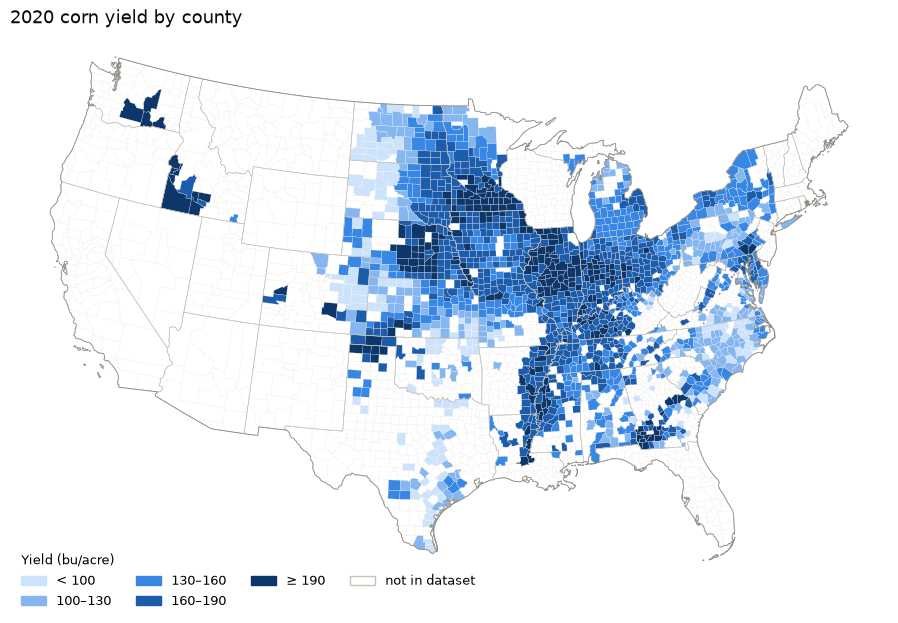

In [148]:

# =============================================================================
#  DISCLAIMER: AI GENERATED
#  MODEL: CLAUDE OPUS 5.5 + high effort
# ===========================================================================

import json
from collections import Counter
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.collections import LineCollection, PolyCollection
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch


COUNTIES_URL = "https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json"


def plot_yield_map(data_path, geojson_url=COUNTIES_URL):
    yld = pd.read_csv(data_path, dtype={"fips": str}).set_index("fips")["yield_bu_acre"]
    rings = {f["properties"]["STATE"] + f["properties"]["COUNTY"]:
             [np.array(p[0]) for p in (g["coordinates"] if g["type"] == "MultiPolygon" else [g["coordinates"]])]
             for f in json.load(urlopen(geojson_url))["features"] for g in [f["geometry"]]
             if f["properties"]["STATE"] not in {"02", "15", "60", "66", "69", "72", "78"}}

    p1, p2, lat0 = np.radians([29.5, 45.5, 37.5])  # Albers equal-area projection
    n = (np.sin(p1) + np.sin(p2)) / 2
    rho = lambda phi: np.sqrt(np.cos(p1) ** 2 + 2 * n * np.sin(p1) - 2 * n * np.sin(phi)) / n
    proj = lambda xy: np.column_stack([rho(np.radians(xy[:, 1])) * np.sin(n * np.radians(xy[:, 0] + 96)),
                                       rho(lat0) - rho(np.radians(xy[:, 1])) * np.cos(n * np.radians(xy[:, 0] + 96))])
    def border(fips):  # edges not shared by two counties in the set
        edges = Counter(tuple(sorted(e)) for f in fips for r in rings[f]
                        for pts in [[tuple(np.round(p, 3)) for p in r]] for e in zip(pts, pts[1:]))
        return [proj(np.array(e)) for e, k in edges.items() if k == 1]

    colors = ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
    fig, ax = plt.subplots(figsize=(12, 7.2))
    ax.add_collection(PolyCollection([proj(r) for f, rs in rings.items() if f not in yld.index for r in rs],
                                     facecolor="white", edgecolor="#ecebe6", lw=0.2))
    have = [(proj(r), yld[f]) for f, rs in rings.items() if f in yld.index for r in rs]
    ax.add_collection(PolyCollection([p for p, _ in have], array=np.array([v for _, v in have]), edgecolor="white", lw=0.15,
                                     cmap=ListedColormap(colors), norm=BoundaryNorm([0, 100, 130, 160, 190, 300], 5)))
    for st in sorted({f[:2] for f in rings}):
        ax.add_collection(LineCollection(border(sorted(f for f in rings if f[:2] == st)), color="#c3c2b7", lw=0.4))
    ax.add_collection(LineCollection(border(sorted(rings)), color="#898781", lw=0.6))
    ax.autoscale_view(); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title("2020 corn yield by county", loc="left", color="#0b0b0b", fontsize=13)
    labels = ["< 100", "100–130", "130–160", "160–190", "≥ 190"]
    ax.legend(handles=[Patch(color=c, label=l) for c, l in zip(colors, labels)]
              + [Patch(facecolor="white", edgecolor="#c3c2b7", label="not in dataset")],
              loc="lower left", bbox_to_anchor=(0.0, -0.06), ncol=4, frameon=False, fontsize=9,
              title="Yield (bu/acre)", title_fontsize=9.5, alignment="left")
    return fig


plot_yield_map("data.csv")
plt.show()

**Figure 1**: above shows the crop yield for each county grouped by state.

Importantly, our dataset has many counties (and even states) missing throughout the US. Indeed, the CropNet dataset only covers 30 of the 50 US states for the year 2020.

---

The machine learning task is a regression task. Our chosen models are a Random Forest Regressor and Elastic Net.
- **Random Forest** is an ensemble model which trains multiple rCART models and averages the result.
- **Elastic Net** is a linear regression model that can use two types of regularization to minimalize overfitting.

We decided to go with these two models as they come from different families (ensemble and linear).

---


In the final dataset we have 1601 samples and 329 columns including the ground truth corn yeild target variable.

The columns and their descriptions are presented in the table below:

Feature Name | Description 
----------------------------------- | -------------------------
`fips` |  Unique identifier of the county in question
`county` | County name
`state` | Abbreviation of State name
`year` | Year (in our case 2020)
`yield_bu_acre` | Yearly yield for the county in bushels per acre
`{month}_temp_mean_k` | Mean monthly temperature in Kelvin
`{month}_temp_std_k` | Monthly standard deviation of the temperature in Kelvin
`{month}_temp_max_k` | Maximum temperature recorded in a given month in Kelvin
`{month}_temp_min_k` | Minimum temperature recorded in a given month in Kelvin
`{month}_precip_mean_mm` | Mean precipitation for a given month in milimiters
`{month}_precip_std_mm` | Monthly standard deviation of precipitation in milimiters
`{month}_rh_mean_pct` | Monthly mean relative humidity in %
`{month}_rh_std_pct` | Monthly standard deviation in relative humidity in %
`{month}_gust_mean_m_s` | Monthly mean gust speed in m/s
`{month}_gust_std_m_s` | Montlhy standard deviation of gust speed in m/s
`{month}_wind_mean_m_s` | Monthly average of the wind speed in a given county in m/s
`{month}_wind_std_m_s` | Standard deviation of the wind seed in a given month in m/s
`{month}_wind_u_mean_m_s` | Mean horizontal wind speed moving towards the East in m/s 
`{month}_wind_u_std_m_s` | Standard deviation of the horizontal wind speed moving towards the East in m/s 
`{month}_wind_v_mean_m_s`| Mean horizontal wind speed moving towards the North in m/s 
`{month}_wind_v_std_m_s`| Standard deviation of the horizontal wind speed moving towards the North in m/s 
`{month}_srad_mean_w_m2`| Monthly mean shortwave radiation the reaches the Earth in W/m2
`{month}_srad_std_w_m2`| Standard deviation of the shortwave radiation the reaches the Earth in W/m2
`{month}_vpd_mean_kpa`| Mean Vapor Pressure Deficit in kPa
`{month}_vpd_std_kpa` | Standard deviation of the monthly Vapor Pressure Deficit in kPa
`{month}_area_km2` | Total county area covered, km² 
`{month}_crop_area_km2`  | Area classified as cropland in that month, km² 
`{month}_ndvi_crop_mean` | Mean NDVI over cropland pixels (NaN when crop area is 0) 
`{month}_ndvi_crop_per_km2` | `ndvi_crop_sum / area_km2` measures total crop 'greenness' per km2 
`{month}_cloud_area_km2` | Cloud-covered area, km² 
`{month}_cloud_per_km2` | `cloud_area_km2 / area_km2`, i.e. cloud fraction 
`{month}_s2_days_since_latest` | Days between the end of the month and the most recent cloud-free Sentinel-2 image (used for that month's Sentinel-2 features)

In [149]:
import pandas as pd

RANDOM_STATE = 52

path = "data.csv"
df = pd.read_csv(path)
print(f"Number of samples: {len(df)}")
print(f"Number of columns: {len(df.columns)}")

target_label = "yield_bu_acre"
non_numeric_labels = ["fips", "county", "state", "year"]
groups = df["state"]

Number of samples: 1601
Number of columns: 329


## Missing values<a id="missing-val"></a> ✅

All missing (NaN) values are in {month}_ndvi_crop_mean. This feature is the summed NDVI over cropland divided by the Dynamic World (DW) crop area.

The months in which the problem occurs are Jnuary, February, March, October and December, which are especially cloudy in the northen hemisfere. Dynamic World sometimes does not detect cropland in these winter months. We therefore set these NaNs to 0.0 (i.e. no average crop NDVI).

In [150]:
# explore the data in regards to no-data values 
missing_values_col_list = []
for col in df.columns:
    sum_nan = df[col].isna().sum()
    if sum_nan != 0:
        print(f'{col}: {sum_nan}')
        missing_values_col_list.append(col)

print("Missing value columns:", missing_values_col_list)
df = df.fillna(0)

jan_ndvi_crop_mean: 116
feb_ndvi_crop_mean: 61
mar_ndvi_crop_mean: 14
oct_ndvi_crop_mean: 2
dec_ndvi_crop_mean: 32
Missing value columns: ['jan_ndvi_crop_mean', 'feb_ndvi_crop_mean', 'mar_ndvi_crop_mean', 'oct_ndvi_crop_mean', 'dec_ndvi_crop_mean']


## Feature Removal<a id="remove"></a> ✅

The table below summarises which features (columns) we decided to remove and why. 

| Features | Columns | Count | Reason |
|---|---|---|---|
| Cloud cover | `{month}_cloud_per_km2`, `{month}_cloud_area_km2` | 24 | 99.6% of values are ~0, and have almost no information. |
| Duplicate county area | `feb_area_km2` … `dec_area_km2` | 11 | County area is the same every month, so 11 columns are duplicates. |
| Winter Sentinel-2 features | `{dec,jan,feb,mar}_{crop_area_km2, ndvi_crop_mean, ndvi_crop_per_km2, s2_days_since_latest}` | 16 | 8–13% of counties have no new Sentinel-2 image in these months. |
| Metadata | `fips`, `county`, `state`, `year` | 4 | These aren't predictive features. |

Refer to the docstrings in the `code` block below for more information on the removal of each respective feature.

Removing redundant / uninformative features early is important for Random Forests to reduce training time (as each split has to be evaluated for each feature).

In [151]:

# =============================================================================
#  DISCLAIMER: AI GENERATED
#  MODEL: CLAUDE OPUS 5.5 + high effort
# ===========================================================================

def _plot_stale_images(df, year=2020, min_label=1):
   ends = pd.date_range(f"{year}-01-01", periods=12, freq="ME")
   back = pd.DataFrame({
      m: e.month + 12 * (e.year - d.dt.year) - d.dt.month
      for m, e in zip(MONTHS, ends)
      for d in [e - pd.to_timedelta(df[f"{m}_s2_days_since_latest"], unit="D")]
   })
   pct = pd.DataFrame({"Previous month": (back == 1).mean(), "2+ months back": (back >= 2).mean()}) * 100
   total = pct.sum(axis=1)
   ax = pct.rename(index=str.capitalize).plot.bar(stacked=True, rot=0, width=0.6, figsize=(9, 4.5),
                                                color=["#86b6ef", "#1c5cab"], edgecolor="white", lw=2)
   ax.bar_label(ax.containers[-1], [f"{v:.0f}%" if v >= min_label else "" for v in total], fontsize=9, padding=2)
   ax.spines[["top", "right", "left"]].set_visible(False)
   ax.grid(axis="y", color="#e1e0d9"); ax.set_axisbelow(True); ax.tick_params(length=0)
   ax.set(ylabel="Counties with no new image (%)", ylim=(0, total.max() * 1.15))
   ax.set_title("Percentage of counties with Sentinel-2 metrics from earlier months")
   ax.legend(frameon=False, title="Latest image taken")
   plt.tight_layout()
   return ax


=== Remove non numeric features ===
Removing non-numeric features...
NUM FEATURES: 329 -> 325

=== Remove duplicate area features ===
County area does not change month-to-month.
Removing all {m}_area_km2 except for one...
NUM FEATURES: 325 -> 314

=== Remove cloud features ===
Percentage Cloud Cover > 0.20: 0.0004
Percentage Cloud Cover < 0.001: 0.9959
Removing Dynamic World cloud / cloud shadow features...
NUM FEATURES: 314 -> 290

=== Remove redundant s2 months ===
Removing monthly s2 features that have counties with image acquisition from previous months...
Removing {m}_s2_days_since_latest as no longer needed...
NUM FEATURES: 290 -> 266


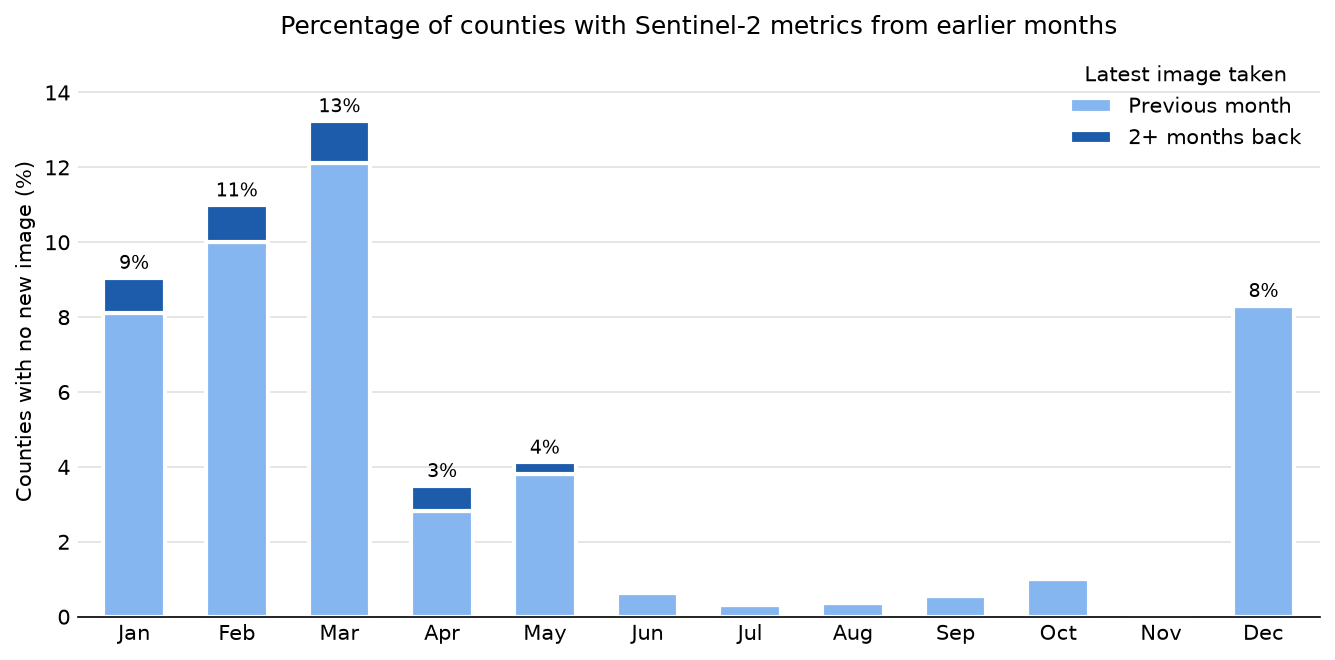

In [152]:
import functools


MONTHS = [
   'jan', 'feb', 'mar', 'apr',
   'may', 'jun', 'jul', 'aug',
   'sep', 'oct', 'nov', 'dec'
]


def log_feat_selection(func):
    @functools.wraps(func)
    def wrapper(df, *args, **kwargs):
        print(f"\n=== {func.__name__.replace("_", " ").capitalize()} ===")
        result = func(df, *args, **kwargs)
        print(f"NUM FEATURES: {df.shape[1]} -> {result.shape[1]}")
        return result
    return wrapper


@log_feat_selection
def remove_non_numeric_features(df, non_numeric_labels):
   print("Removing non-numeric features...")
   return df.drop(non_numeric_labels, axis=1)


@log_feat_selection
def remove_duplicate_area_features(df):
   """Remove redundant area features.
   
   The data processing notebook calculated the area of a county for 
   each month of the year. Of course, the area of a county does not change 
   month-to-month, so we can drop 11 of these 12 features.
   """
   area_columns = [f"{m}_area_km2" for m in MONTHS]
   print(f"County area does not change month-to-month.")
   print("Removing all {m}_area_km2 except for one...")

   df = df.rename(columns={"jan_area_km2": "area_km2"})
   return df.drop(area_columns[1:], axis=1)


@log_feat_selection
def remove_cloud_features(df):
   """Remove uninformative cloud statistics.

   The data processing notebook filters images using ESA's cloud mask.
   It filters out images with cloud cover greater than 20.0%. As a sanity check,
   we then calculated statistics using Dynamic World cloud / cloud shadow mask.

   The ESA cloud mask filter effectively removed all images with cloud,
   so these statistics are mostly 0.0, hence why we are removing these features.
   """
   cloud_frac_columns = [f"{m}_cloud_per_km2" for m in MONTHS]
   total_gt_20 = (df[cloud_frac_columns] > 0.20).sum().sum()
   total_eq_0 = (df[cloud_frac_columns] < 0.001).sum().sum()

   print(f"Percentage Cloud Cover > 0.20: {total_gt_20/(len(df)*len(MONTHS)):.4f}")
   print(f"Percentage Cloud Cover < 0.001: {total_eq_0/(len(df)*len(MONTHS)):.4f}")
   print("Removing Dynamic World cloud / cloud shadow features...")

   cloud_columns = cloud_frac_columns + [f"{m}_cloud_area_km2" for m in MONTHS]
   return df.drop(cloud_columns, axis=1)


@log_feat_selection
def remove_redundant_s2_months(df):
   """Remove s2 image features for months with no cloud-free image acquisition.

   As a result of the cloud filtering (in the processing notebook), some months
   end up with images from the previous month (and sometimes the month before that!).
   These features are then, of course, very correlated, as they share the same data.

   We found that the months dec - mar suffer from this problem most (the cloudy months),
   and so we drop the S2 features for those months. These are, conveniently, not
   growing months for corn and are likely safe to remove.

   NOTE: this problem plagues the original CropNet dataset too (as they acquire S2 
         images the same way), but they fail to mention or account for this in their
         paper.
   """
   _plot_stale_images(pd.read_csv(path))
   months_to_drop = ["dec", "jan", "feb", "mar"]
   s2_features = ["crop_area_km2", "ndvi_crop_mean", "ndvi_crop_per_km2"]
   s2_columns = [f"{m}_{f}" for m in months_to_drop for f in s2_features]
   print("Removing monthly s2 features that have counties with image acquisition from previous months...")
   df = df.drop(s2_columns, axis=1)

   # we also delete this s2_days_since_latest features, as they were 
   # simply used to identify problematic S2 month features per county.
   days_since_latest_column = [f"{m}_s2_days_since_latest" for m in MONTHS]
   print("Removing {m}_s2_days_since_latest as no longer needed...")
   return df.drop(days_since_latest_column, axis=1)


df = remove_non_numeric_features(df, non_numeric_labels)
df = remove_duplicate_area_features(df)
df = remove_cloud_features(df)
df = remove_redundant_s2_months(df)

plt.show()

**Figure 2**: In the processing notebook, Sentinel-2 images for a month are taken by looking 180 days back 
from the end of the target month (e.g. Jan 31st). The most recent image is used as that month's image (identical to the CropNet dataset).
Some counties are completely cloudy in certain months, so the image for that month can come from a previous month (e.g. Dec or even Nov).
The figure shows the percentage of counties with no Sentinel-2 image acquisition in the target month.

## Methodology

### Grouping

Corn crop yield for counties in the same state exhibit high spatial autocorrelation (due to similar weather and general growing conditions). This informs our decision to use **state** as a grouping variable. 

As mentioned, the dataset is missing many states throughout the US. This means that our machine learning models need to predict for states that *they have never seen* (i.e. should perform well on states not in the training set). Corn crop yield in counties within the same state exhibit high spatial autocorrelation (due to, for example, similar weather and general growing conditions). 




### **Nested Cross-Validation**<a id="cross-val"></a>

# TODO: Using the nested cross-validation strategy ensures that the only assertion that we're making is if you use this grid search approach with these params you can expect a generalisation error in this range.

As mentioned in the introduction our dataset consists of 1601 samples. To our knowleage a dataset of this size should be considered as a small dataset. Because of that a decision was made to use **nested cross-validation**. This workflow will let us tune the hyper-parameters as well as test generalization performacne of the models against multiple train/test splits without any data leakage. 

The strategy choosen for cross-validation is the **Stratified Group K-Folds** with 5 outer folds (keeping the test dataset at ~20% of the dataset) and 4 inner folds.

Due to our datasets character we needed to consider two things:
1. Grouping: as our dataset is spatial we needed to devide it into regions. The regions (or groups for the Group K-Folds) are set as the US states, as the corn yeild within them presents spatial autocorrelation. 

2. Binning: our target varaible is a continous value, due to that we needed to create artificial bins to be sampled. We decided on the equal-interval bins to keep the homogeninty within each stratum (assumption of stratified sampling) and keep the number of bins to 5, so that each stratum had enough samples to be represented in each fold.


As presented in figure 2, the Stratified Group K-Fold chooses the initial groups (or the US states) to set asside for testing in the outer loop (the groups are choosesn in a way that agrees with the stratification) and then the remaining groups are split into train and validation within the inner folds.


In [153]:
from sklearn.model_selection import StratifiedGroupKFold

Y_BINS = 5
OUTER_SPLITS = 5
INNER_SPLITS = 4

X = df.drop(columns=target_label)
y = df[target_label]
outer_cv = StratifiedGroupKFold(n_splits=OUTER_SPLITS, shuffle=True, random_state=RANDOM_STATE)
inner_cv = StratifiedGroupKFold(n_splits=INNER_SPLITS, shuffle=True, random_state=RANDOM_STATE)

# using the equal-interval binning to keep homogeneity within the stratum
y_bin = pd.cut(y, Y_BINS, labels=False)

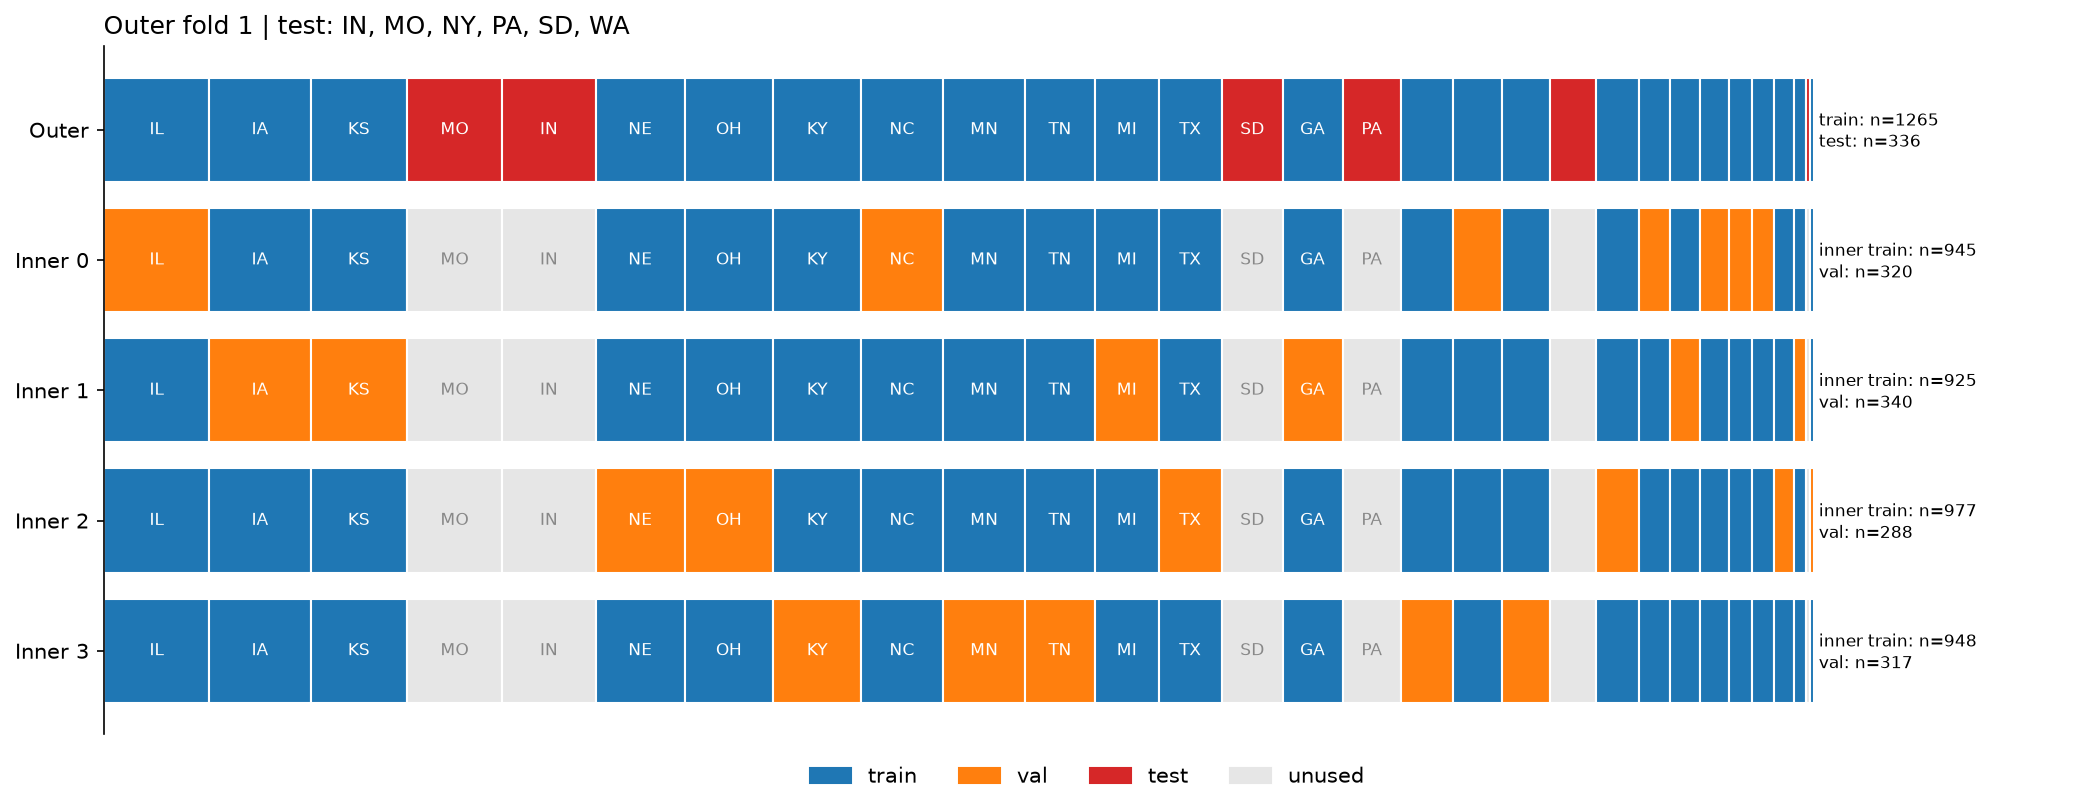

In [154]:
# =============================================================================
#  DISCLAIMER: AI GENERATED
#  MODEL: CLAUDE OPUS 5.5 + high effort
# ===========================================================================

from matplotlib.patches import Patch

COLORS = {"train": "#1f77b4", "val": "#ff7f0e", "test": "#d62728", "unused": "#e6e6e6"}

def plot_outer_fold(outer_idx, y_bin, groups, outer_cv, inner_cv):
    """Plot one outer fold and its inner splits, one block per group."""
    y, groups = np.asarray(y_bin), np.asarray(groups)
    X_dummy = np.zeros(len(y))                      # splitters only need the length
    order = pd.Series(groups).value_counts()        # largest group first

    train_idx, test_idx = list(outer_cv.split(X_dummy, y, groups))[outer_idx]

    # One role per sample for each row of the plot
    outer = np.where(np.isin(np.arange(len(y)), test_idx), "test", "train")
    rows = [("Outer", outer)]
    for k, (itr, iva) in enumerate(inner_cv.split(X_dummy[train_idx], y[train_idx], groups[train_idx])):
        roles = np.full(len(y), "unused", dtype=object)
        roles[train_idx[itr]] = "train"             # map back to original positions
        roles[train_idx[iva]] = "val"
        rows.append((f"Inner {k}", roles))

    fig, ax = plt.subplots(figsize=(14, 0.8 * len(rows) + 1.5))
    for r, (label, roles) in enumerate(rows):
        left = 0
        for g, size in order.items():
            role = roles[groups == g][0]            # a group never spans two roles
            ax.barh(r, size, left=left, color=COLORS[role], edgecolor="white")
            if size / len(y) >= 0.03:
                ax.text(left + size / 2, r, g, ha="center", va="center", fontsize=8,
                        color="#888" if role == "unused" else "white")
            left += size

        n_train = (roles == "train").sum()
        if label == "Outer":
            text = f"train: n={n_train}\ntest: n={(roles == 'test').sum()}"
        else:
            text = f"inner train: n={n_train}\nval: n={(roles == 'val').sum()}"
        ax.text(left + 5, r, text, va="center", fontsize=8, linespacing=1.3)

    ax.set_xlim(0, len(y) * 1.15)                   # leave room for the labels
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([r[0] for r in rows])
    ax.invert_yaxis()
    ax.set_xticks([])
    ax.spines[["top", "right", "bottom"]].set_visible(False)
    ax.set_title(f"Outer fold {outer_idx} | test: {', '.join(sorted(set(groups[test_idx])))}", loc="left")
    ax.legend(handles=[Patch(color=c, label=k) for k, c in COLORS.items()],
              ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.02), frameon=False)
    fig.tight_layout()
    return fig

plot_outer_fold(1, y_bin, groups, outer_cv, inner_cv)
plt.show()

**Figure 2:** Presents the train, validation and test sets selected for an outer and all inner folds of our stratified group k-folds cross-validation strategy. As states are our grouping measure if a state is choosen for the test set (red) then the counties from this state are compleatly eliminated from further sampling.  

## Metrics: 
The metrics used for model evaluation will be:
- mean absolute error (mae) - measures the average magnitude of the errors comitted by a model in the target varables unit of measurement, presents less sensitivity to outliers than rmse
- root mean squared error (rmse) - provides higher sensitivity to outliers
- R-squared (r2) - explains how much of the varability in the target varible is explained by the model (R-squared = 1, means that all of the varaibility is explained by the model)
- time taken to fit the model (fit_time) - measures how long did the model need to be trained

In [155]:
import time

from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline

NUM_TREES_START = 10
NUM_TREES_STEP = 10
MAX_TREES = 1000

def tune_num_trees(estimator, X_train, y_train, inner_splits):
    """Function called within the evaluate_model function when the 
    model to be evaluated is a Random Forest. 
    
    This function performs the "tuning" of the number of trees in
    the forest by selecting the number of trees that is within 1 
    standard error of the best performing model, ensuring the model 
    reatches a plateau but also optimizing the time needed to train 
    the models.

    We decided to tune the number of trees before doing the grid 
    search due to practical reasons as training many models with a 
    big number of trees is very time consuming.
    """
    results = {}
    for inner_fold, (inner_train_idx, val_idx) in enumerate(inner_splits):
        X_inner_train, X_val = X_train.iloc[inner_train_idx], X_train.iloc[val_idx]
        y_inner_train, y_val = y_train.iloc[inner_train_idx], y_train.iloc[val_idx]

        accuracies = []
        rf = clone(estimator).set_params(randomforestregressor__warm_start=True)
        for n in range(NUM_TREES_START, MAX_TREES+1, NUM_TREES_STEP):
            rf.set_params(randomforestregressor__n_estimators=n)

            rf.fit(X_inner_train, y_inner_train)   # add one tree
            score = r2_score(y_val, rf.predict(X_val))
            accuracies.append(score)

        results[inner_fold] = accuracies

    results_df = pd.DataFrame(results)

    n_trees = np.arange(NUM_TREES_START, MAX_TREES+1, NUM_TREES_STEP)
    avg_scores = results_df.mean(axis=1).to_numpy()
    avg_scores_se = avg_scores.std() / np.sqrt(len(avg_scores))

    best_idx = np.argmax(avg_scores)
    lower_bound = avg_scores[best_idx] - avg_scores_se
    chosen_n = n_trees[np.argmax(avg_scores >= lower_bound)]
    
    plot_num_trees(results_df, n_trees, chosen_n, se=avg_scores_se)
    plt.show()

    return chosen_n



def plot_num_trees(results_df, n_trees, chosen_n, se=None):
    
    #TODO: AI DISCLAIMER????
    
    mean = results_df.mean(axis=1).to_numpy()
    std = results_df.std(axis=1).to_numpy()
    best = np.argmax(mean)
    chosen = list(n_trees).index(chosen_n)
 
    plt.figure(figsize=(8, 5))
    plt.plot(n_trees, results_df, color="lightgray", lw=1)
    plt.fill_between(n_trees, mean - std, mean + std, alpha=0.15, label="±1 std")
    plt.plot(n_trees, mean, lw=2, label="Mean score")
    if se is not None:
        plt.axhline(mean[best] - se, color="gray", ls=":", label="Best − 1 SE")
 
    plt.axvline(n_trees[best], color="red", ls="--", alpha=0.5)
    plt.axvline(chosen_n, color="green", ls="--", alpha=0.5)
    plt.plot(n_trees[best], mean[best], "o", color="red", ms=8, mec="white",
             label=f"Best: {n_trees[best]} trees ({mean[best]:.3f})")
    plt.plot(chosen_n, mean[chosen], "o", color="green", ms=8, mec="white",
             label=f"Chosen: {chosen_n} trees ({mean[chosen]:.3f})")
 
    plt.title("Validation score vs. number of trees")
    plt.xlabel("Number of trees")
    plt.ylabel("Validation R²")
    plt.legend(loc="lower right", frameon=False)
    plt.grid(alpha=0.3)
    plt.gca().spines[["top", "right"]].set_visible(False)


def evaluate_model(model, X, y, y_bin, groups, outer_cv, inner_cv):
    """Function performing nested Stratified Group K-Folds 
    cross-validation with hyper-parameter tunning of a ML model.

    Parameters
    ===========
    - model: the model defined as a touple of the estimator 
    and it's hyperparemter grid (as a dictionary) to be used in 
    GridSearchCV
    - X: the training data
    - y: the target varaible
    - y_bin: the binning strategy for the Stratified Group 
    K-Folds
    - groups: groups for the Stratified Group K-Folds
    - outer_cv: defined Stratified Group K-Folds instance 
    for the outer loop
    - inner_cv: defined Stratified Group K-Folds instance 
    for the inner loop

    Returns
    ==========
    - a pandas data frame with the performance measures of the 
    model in question for each outer fold
    """
    rows = []
    for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, y_bin, groups)):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        estimator, grid = model
        inner_splits = list(inner_cv.split(X_train, y_bin.iloc[train_idx], groups.iloc[train_idx]))

        if estimator.steps[-1][0] == "randomforestregressor":
            num_trees = tune_num_trees(estimator, X_train, y_train, inner_splits)
            estimator.set_params(randomforestregressor__n_estimators=num_trees)

        scoring = "neg_mean_squared_error"
        # clone(...) ensures that the model parameters of the estimator are not updated.
        # GridSearchCV returns an instance of a fitted estimator.
        search = GridSearchCV(clone(estimator), grid, cv=inner_splits, scoring=scoring, n_jobs=-1)

        t0 = time.perf_counter()
        final_model = search.fit(X_train, y_train)
        fit_time = time.perf_counter() - t0

        train_error = final_model.predict(X_train)

        t0 = time.perf_counter()
        pred = final_model.predict(X_test)
        predict_time = time.perf_counter() - t0

        rows.append({
            "fold": fold,
            "best_params": final_model.best_params_,
            "train_mae": mean_absolute_error(y_train, train_error),
            "train_rmse": root_mean_squared_error(y_train, train_error),
            "train_r2": r2_score(y_train, train_error),
            "test_mae": mean_absolute_error(y_test, pred),
            "test_rmse": root_mean_squared_error(y_test, pred),
            "test_r2": r2_score(y_test, pred),
            "fit_time": fit_time,
            "predict_time": predict_time,
        })

    return pd.DataFrame(rows)

## **Feature selection within the pipelines:**
We decided it woud be interesting to include a custom feture selection algorithm within the model pipelines to check weather the models performace would be highly dependant on the numbr of features it's working with.

The custom feature selector has two options either it keeps the features for the entire year (so all months form January to December) or only considers the features which months correspond to the growing seson of corn (from april till october).

In [156]:
from sklearn.base import BaseEstimator, TransformerMixin

class SesonalFeatureSelector(BaseEstimator, TransformerMixin):
    """This custom feature selector depending on the setting 
    either keeps all of the features for the entire year or 
    selects features that are connected to the growing seson 
    of corn (april to october).

    Parameters
    ==============
    time_period: str or None
    the time period of the features of interest 
     - for the growing season features the "growing_season" 
    option should be selected. 
     - any other str value or None are equal to all year 
     features for corn.

    fit(X, y=None)
    =================
    Check the columns of X.

    transform(X)
    =================
    Reduce X to the selected feature columns.

    Implemented based on: 
    https://medium.com/@benjybo7/3-steps-to-implement-a-custom-feature-selector-in-python-116f114e15ad
    """
    def __init__(self, time_period=None):
        self.time_period = time_period


    def fit(self, X, y=None):
        self.columns_ = X.columns
        return self

    def transform(self, X):
        if self.time_period == "growing_season":
            months = ("jan", "feb", "mar", "nov", "dec")
            col_list = [col for col in self.columns_ if col.startswith(months)]
            X_dropped = X.drop(columns=col_list)
            return X_dropped
        else:
            return X


## **Dummy regressor**<a id="dummy"></a>

The dummy regressor is a model that assigns the same value to the prediction, in our case this prediction is going to be the mean value of the yeild. The dummy regressor will be used as a baseline mdel to be compared with our predictions.

In [157]:
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
pd.set_option('display.max_colwidth', None)

dummy = (
            make_pipeline(SesonalFeatureSelector(), DummyRegressor()),
            {
                "sesonalfeatureselector__time_period": ["all_year", "growing_season"],
                "dummyregressor__strategy": ["mean"]
            },
        )

result_dummy = evaluate_model(dummy, X, y, y_bin, groups, outer_cv, inner_cv)
result_dummy.to_csv("dummy_result")
display(result_dummy)

,fold,best_params,train_mae,train_rmse,train_r2,test_mae,test_rmse,test_r2,fit_time,predict_time
0,0,"{'dummyregressor__strategy': 'mean', 'sesonalfeatureselector__time_period': 'all_year'}",29.118446,35.955075,0.0,28.851786,36.005063,-0.003427,3.049110,0.000210
1,1,"{'dummyregressor__strategy': 'mean', 'sesonalfeatureselector__time_period': 'all_year'}",29.935525,36.766868,0.0,26.676957,32.811121,-0.014797,0.079890,0.000046
2,2,"{'dummyregressor__strategy': 'mean', 'sesonalfeatureselector__time_period': 'all_year'}",29.088985,35.752271,0.0,28.950223,36.927259,-0.004242,0.080769,0.000047
3,3,"{'dummyregressor__strategy': 'mean', 'sesonalfeatureselector__time_period': 'all_year'}",29.387141,36.261044,0.0,28.574508,34.811514,-0.008099,0.088473,0.000052
4,4,"{'dummyregressor__strategy': 'mean', 'sesonalfeatureselector__time_period': 'all_year'}",28.106938,35.068673,0.0,33.234942,39.717095,-0.005703,0.064064,0.000042


## **Random Forest**<a id="rf"></a>

The Random Forest is an ensamble estimator which uses averaging of multiple Decision Tree model predictions on bootstrap samples of the original dataset to obtain the final target prediction. The use of multiple Decision Trees is supposed to minimalize the varaince of the model, by aggregating the results of all of the trees in the end. Additionally, for each split in the Decision Tree Random Forest uses a random subset of features to additionally lower the corelation between the samples. Thouse two steps are supposed to minimalize the risk of overfitting (if the number of trees is high enough).

#### Why did we select to work on Random Forest?
Our dataset consists of features with different scales and even different units of measurement, so Random Forest seemed to be a good choice. Random Forest with low values of max_features can also handle correlated features.

#### Hyperparameters to tune:
- **`n_estimators`**: number of decision trees in the forest (the bigger the more stable the prediction)
- **`max_features`**: procentage of randomly choosen features used to split each node (if 1 then all of the features are used)
- **`max_samples`**: number of data points in the bootstrap samples (if 1 the bootstrap samples are of the same size as the original dataset)
- **`min_samples_split`**: minimal numbr of samples per node that can be still split 

#### Advantages:
- can be used for both regression and classification problems
- less prone to overfitting then the Decision Tree model
- good at handeling different scales of data, missing values and outliers

#### Disadvantages/ Challanges:
- multiple hyperparameters to tune (bigger grid for GridSearchCV)
- time and memory consuming training

---

Choice of the hyper-parameter grid:


For min_samples_split we decided o 3 values to tune 2, 5 and 10 as we want the trees to grow quite deep as overfitting due to bagging is not a big problem. We are testig a wide range of values for max_features and max_samples.

We run into some problems with tunnig the number of trees inside the nested cross-validation. We decided, that due to computational reasons, we will tune the number of trees first (taking the value in range of 1 standard error of the number of tree when the model scores the best) on a model with reasonable other hyperparameters. After the number of trees is settled we then perform hyper-parameter tunning using GridSearchCV.

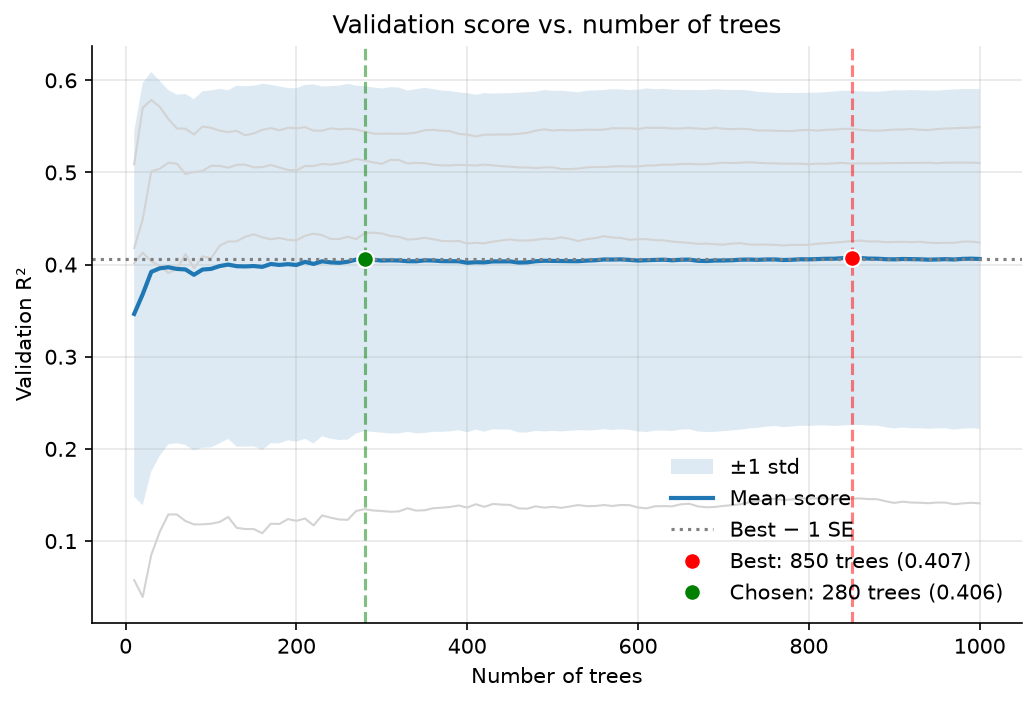

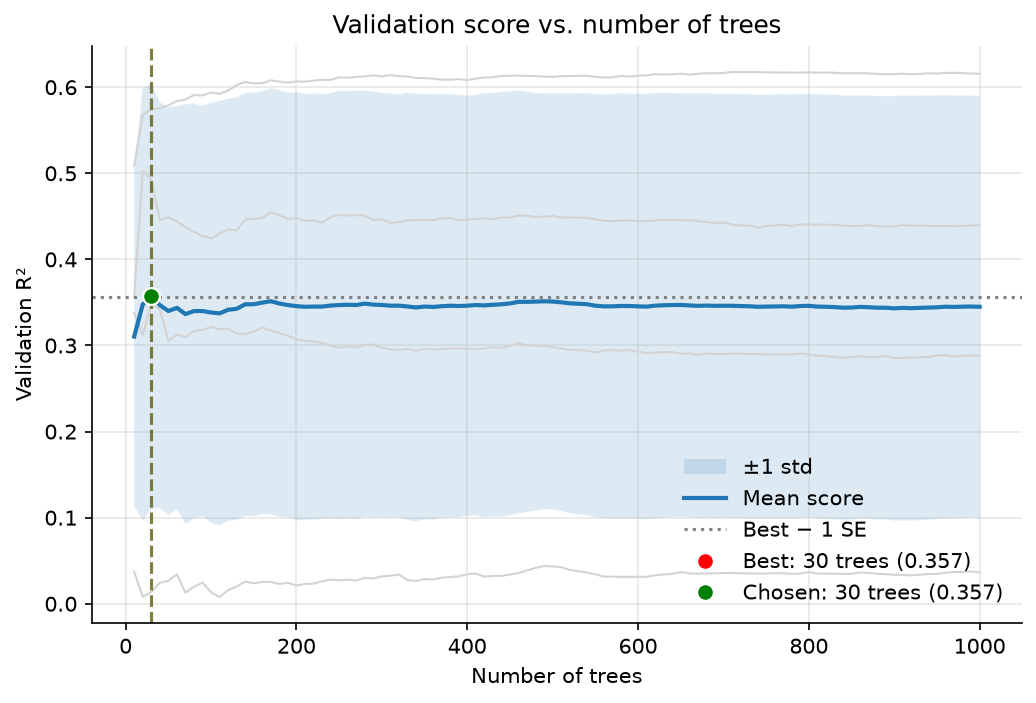

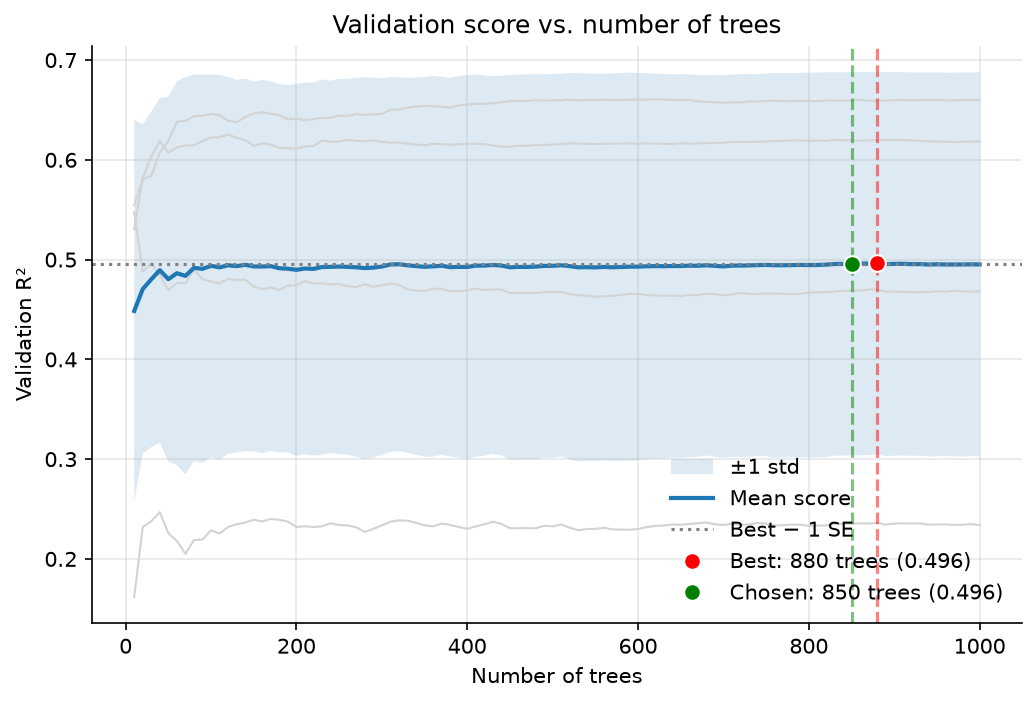

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf = (
    # ParamGrid is already parallelised, so we set n_jobs=1 here.
    make_pipeline(SesonalFeatureSelector(), RandomForestRegressor(max_features=0.333, random_state=RANDOM_STATE, n_jobs=1, bootstrap=True)),
    {
        "sesonalfeatureselector__time_period": ["all_year", "growing_season"],
        "randomforestregressor__max_features": [0.2, 0.333, 0.5, 0.75, 1.0],
        "randomforestregressor__min_samples_split": [2, 5, 10],
        "randomforestregressor__max_samples": [0.5, 0.75, 0.9, 1.0],
    },
)

result_rf = evaluate_model(rf, X, y, y_bin, groups, outer_cv, inner_cv)
result_rf.to_csv("rf_results.csv")

display(result_rf)

# todo: max_features 0.3333 affects model variance in rf graphs

## **ElasticNet regression**<a id="elastic-net"></a>

ElasticNet regression model is a linear regression model with included additional regularization to minimalize model complexity and avoid overfitting. Elastic Net includes both the L1-norm and L2-norm, combining the feature selection capabilities of LASSO regression and the shared weights of correlated varaibles of the Ridge regression algorithm. ElasticNet allows for flexibilility when choosing the regulrization that should be more penalized with it's hyper-parameters.

#### Why did we decide on ElasticNet?
Our features are characterized by two things firstly there is a lot of them, secondly they show quite high values of correlation between one another as they are aggregated fetures. For some of the features thier correlation comes from even the definition of the feature. For thouse reasons we decided that ElascticNet is going to be a suitable model for our task.

#### Hyperparameters to tune:
- **`alpha`**: the regulariztion parameter which controls the amount of regularization on the model (can go from 0 to +∞, where 0 is no regularization so a standard linear regression and +∞ sets the beta parameters to 0 so maximal regularization possible)
- **`l1_ratio`**: the importance of the L1 penalty or the mixinig parameter, the value can be in range from 0 to 1, where 0 means pure L2 penalty (Ridge regression)and 1 means pure L1 penalty (LASSO regression).

#### Advantages:
- flexibilility with regularization techniques 
- possible feature selection to shink model complexity
- able to deal with correlated varaibles 

#### Disadvantages:
- features have to be scaled before using Elastic Net
- the alpha paramiter doesn't have a range (can go from 0 to +∞) so it's not easy to tune it's value

---

Choice of the hyper-parameter grid:

Because our dataset, even after feature selection has many features, we knew that some regularization will be needed so for this reason the grid for the `alpha` parameter starts at 4. For `l1_ratio` we decided to test the entire spectrum of possible values.

In [154]:
from sklearn.linear_model import ElasticNet
from sklearn.preprocessing import StandardScaler

elastic_net = (
        make_pipeline(SesonalFeatureSelector(), StandardScaler(), ElasticNet(random_state = RANDOM_STATE)),
        {
            "sesonalfeatureselector__time_period": ["all_year", "growing_season"],
            "elasticnet__alpha": [4, 6, 8, 10, 25, 50, 75, 100, 250, 500, 750, 1000],
            "elasticnet__l1_ratio": [0.01, 0.1, 0.25, 0.35, 0.5, 0.75, 0.9, 0.95, 1.0]
        },
)

result_elastic_net = evaluate_model(elastic_net, X, y, y_bin, groups, outer_cv, inner_cv)
display(result_elastic_net)

,fold,best_params,test_error_mae,test_error_rmse,test_error_r2,mae,rmse,r2,fit_time,predict_time
0,0,"{'elasticnet__alpha': 4, 'elasticnet__l1_ratio': 1.0, 'sesonalfeatureselector__time_period': 'growing_season'}",17.605912,23.378644,0.577216,23.423690,30.462435,0.281730,10.830002,0.006626
1,1,"{'elasticnet__alpha': 4, 'elasticnet__l1_ratio': 1.0, 'sesonalfeatureselector__time_period': 'growing_season'}",19.787073,25.689238,0.511810,16.686330,23.119675,0.496151,10.620036,0.006915
2,2,"{'elasticnet__alpha': 4, 'elasticnet__l1_ratio': 1.0, 'sesonalfeatureselector__time_period': 'growing_season'}",18.486147,24.396200,0.534374,21.504925,27.450258,0.445071,9.649734,0.007073
3,3,"{'elasticnet__alpha': 4, 'elasticnet__l1_ratio': 0.95, 'sesonalfeatureselector__time_period': 'growing_season'}",19.592207,25.830390,0.492564,20.584421,27.003629,0.393401,9.594669,0.007405
4,4,"{'elasticnet__alpha': 4, 'elasticnet__l1_ratio': 1.0, 'sesonalfeatureselector__time_period': 'growing_season'}",18.738425,25.071093,0.488898,22.053398,27.628910,0.513322,10.271206,0.011936


## **Additional features**

After the initial experiments with the models we realised that their performance is not very impressive. We did some additional research and found a feature that could help our predictions. 


It turns out that there are two types of corn fileds. There is: dry land corn and irrigated corn [Nebraska Corn Board](https://nebraskacorn.gov/cornstalk/water-and-resources/whats-the-difference-between-dry-land-corn-and-irrigated-corn/). The differance between them is that the irrigated corn gets additional water during dry sesons while dry land corn relies only on rainfall. Due to our weather derived features the irrigation can impact the predictions quite sevirly. 


The new feature: 
- `irrigated_share`: which is the percentege of crops per county that are irrigated

We decided to include this features, retrain the models and check their performance.

## **Discussion of results**<a id="discussion"></a>

### Original results

### Results after adding the irrigation data